In [3]:
import ast
from pathlib import Path

import h5py
import numpy as np

DATA_ROOT = Path("/data/optimisation/measured_data")  # folder that contains the acquisition_* runs


def find_chunks(root=DATA_ROOT):
    """{run name: sorted list of chunk paths} for every acquisition_*/h5/chunk_*.h5 under root."""
    runs = {}
    for run in sorted(root.glob("acquisition_*")):
        chunks = sorted((run / "h5").glob("chunk_*.h5"))
        if chunks:
            runs[run.name] = chunks
    return runs


def is_ragged(obj):
    return isinstance(obj, h5py.Group) and bool(obj.attrs.get("ragged", False))


def list_variables(path):
    """All variable names in a chunk; a ragged group counts as one variable (its shot_* datasets are skipped)."""
    names = []

    def visit(name, obj):
        parent = name.rsplit("/", 1)[0] if "/" in name else ""
        if parent and is_ragged(f[parent]):
            return
        if isinstance(obj, h5py.Dataset) or is_ragged(obj):
            names.append(name)

    with h5py.File(path, "r") as f:
        f.visititems(visit)
    return names


def decode(x):
    """bytes -> str; pyda reprs stored as text -> their value (Boolean -> bool, EnumItem -> name)."""
    if not isinstance(x, bytes):
        return x
    s = x.decode()
    if s.startswith("pyda.data.Boolean"):
        return ast.literal_eval(s.split("'value': ")[1].split(",")[0])
    if s.startswith("pyda.data.EnumItem"):
        return s.split("'name': ")[1].split("'")[1]
    return s


def read_variable(f, name):
    """One chunk's array of a variable, shot on axis 0. Ragged groups are NaN-padded to the longest shot."""
    obj = f[name]
    if isinstance(obj, h5py.Dataset):
        a = obj[()]
    else:
        shots = [obj[k][()] for k in sorted(obj)]
        out = np.full((len(shots), max(len(s) for s in shots)), np.nan)
        for i, s in enumerate(shots):
            out[i, : len(s)] = s
        a = out
    if a.dtype.kind in "OS":
        a = np.array([decode(x) for x in a], dtype=object)
    return a


def _pad(a, width):
    """NaN-pad axis 1 to width (ragged lengths can differ between chunks)."""
    if a.ndim < 2 or a.shape[1] == width:
        return a
    out = np.full((a.shape[0], width, *a.shape[2:]), np.nan)
    out[:, : a.shape[1]] = a
    return out


def load_dataset(path, variable, squeeze=True):
    """
    Full array of one variable, shots concatenated in chunk order.
    path: a chunk file, a run folder (acquisition_*), a run name from find_chunks(), or a list of chunk files.
    Chunks without the variable are filled with NaN (None for strings). squeeze=True turns (n, 1, L) into (n, L).
    Beware: BTV0125/image2D is ~470 MB per chunk.
    """
    if isinstance(path, (list, tuple)):
        files = [Path(p) for p in path]
    else:
        p = Path(path)
        if not p.exists():
            p = DATA_ROOT / p                        # run name only
        files = sorted((p / "h5").glob("chunk_*.h5")) if p.is_dir() else [p]
    if not files:
        raise FileNotFoundError(f"no chunks for {path}")

    parts, missing = [], []
    for fp in files:
        with h5py.File(fp, "r") as f:
            if variable in f:
                parts.append(read_variable(f, variable))
            else:
                parts.append(int(f.attrs["n_shots"]))  # placeholder: number of shots to fill
                missing.append(fp.name)
    arrays = [a for a in parts if isinstance(a, np.ndarray)]
    if not arrays:
        raise KeyError(f"{variable} not in any of {len(files)} chunk(s)")
    if missing:
        print(f"{variable}: missing in {len(missing)} chunk(s), filled: {missing}")
    ref = arrays[0]
    width = max(a.shape[1] for a in arrays) if ref.ndim > 1 else None
    fill = np.nan if ref.dtype.kind in "fiu" else None
    parts = [np.full((a, *ref.shape[1:]), fill, dtype=float if fill is not None else object)
             if isinstance(a, int) else a for a in parts]
    out = np.concatenate([_pad(a, width) for a in parts]) if width else np.concatenate(parts)
    if squeeze and out.ndim == 3 and out.shape[1] == 1:
        out = out[:, 0]
    return out


runs = find_chunks()
for name, chunks in runs.items():
    print(f"{name}: {len(chunks)} chunks")

acquisition_2026-10-06_21-57-43: 226 chunks
acquisition_2026-10-07_20-55-58: 5 chunks
acquisition_2026-10-07_21-42-34: 1 chunks
acquisition_2026-10-07_21-43-26: 72 chunks
acquisition_2026-10-08_00-08-19: 255 chunks
acquisition_2026-10-08_15-42-27: 121 chunks
acquisition_2026-10-08_21-11-47: 200 chunks
acquisition_2026-10-09_07-46-07: 110 chunks
acquisition_2026-10-09_11-48-33: 186 chunks


In [16]:
name_map = []
for name in runs:
    name_map.append( name )
print( name_map )

['acquisition_2026-10-06_21-57-43', 'acquisition_2026-10-07_20-55-58', 'acquisition_2026-10-07_21-42-34', 'acquisition_2026-10-07_21-43-26', 'acquisition_2026-10-08_00-08-19', 'acquisition_2026-10-08_15-42-27', 'acquisition_2026-10-08_21-11-47', 'acquisition_2026-10-09_07-46-07', 'acquisition_2026-10-09_11-48-33']


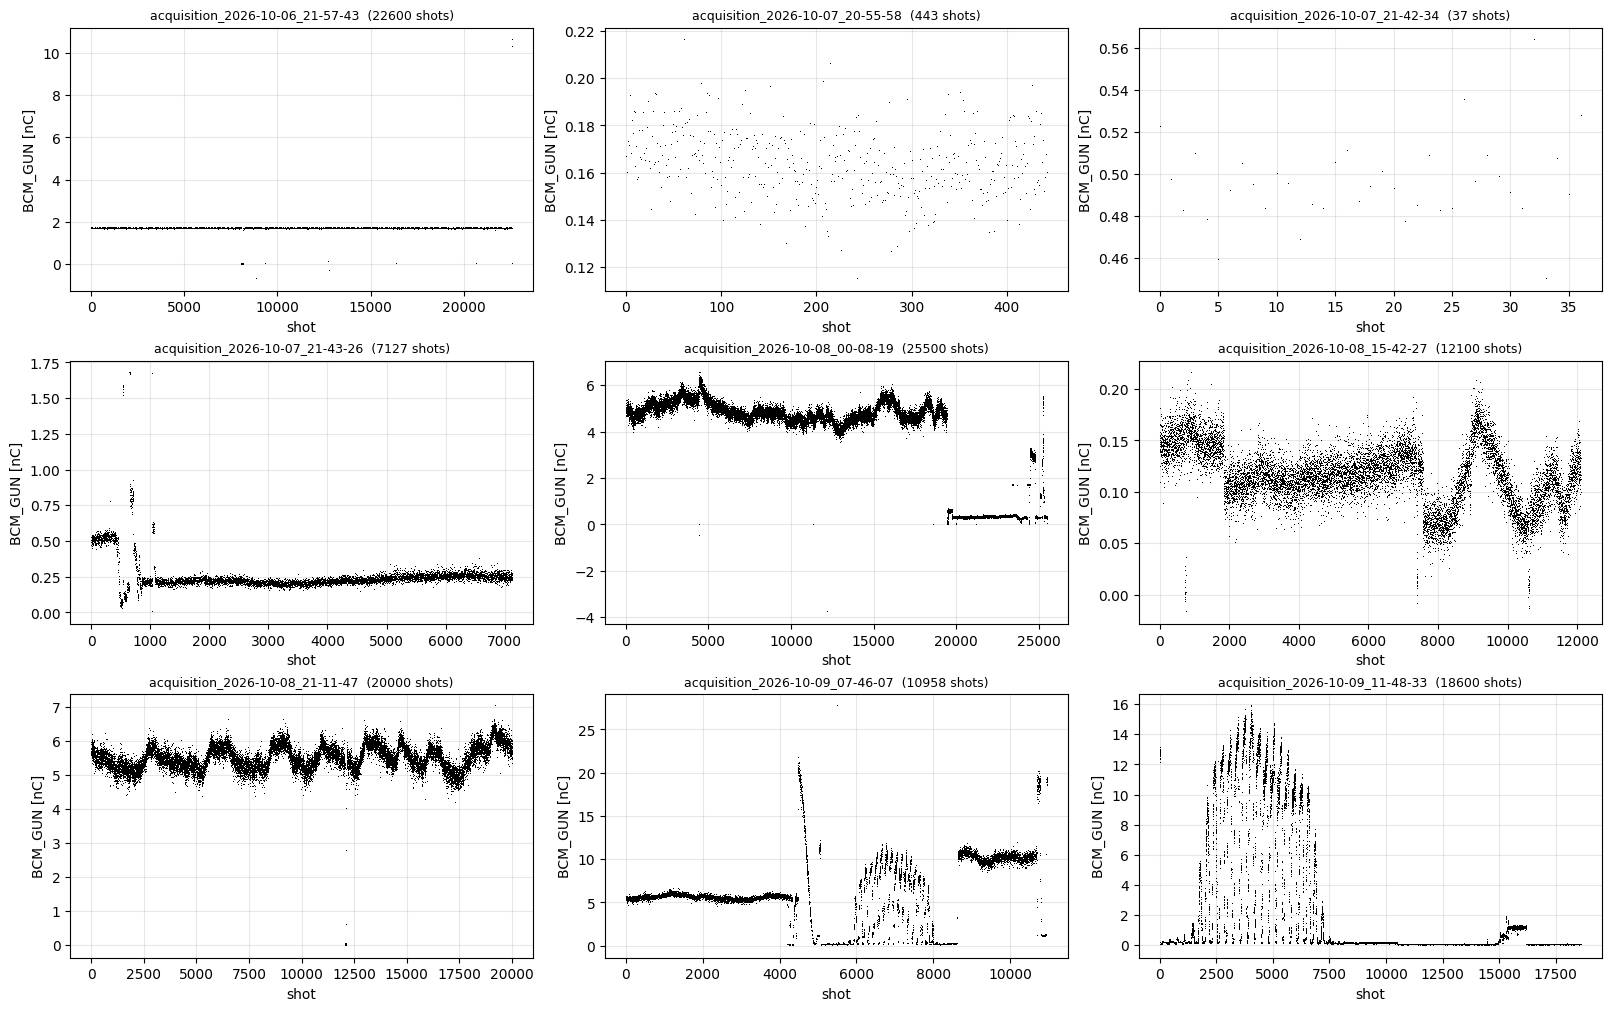

In [12]:
# charge evolution for all runs

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(16, 10), constrained_layout=True)
for ax, run in zip(axes.flat, runs):
    q = load_dataset(run, "BCM_GUN")
    ax.plot(q, ",", color="k")
    ax.set_title(f"{run}  ({len(q)} shots)", fontsize=9)
    ax.set_xlabel("shot")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.grid(alpha=0.3)
for ax in list(axes.flat)[len(runs):]:   # hide unused panels if fewer than 9 runs
    ax.set_visible(False)

fig.savefig("../results/data_labelling/bcm_runs.png", dpi=150, bbox_inches="tight")
plt.show()

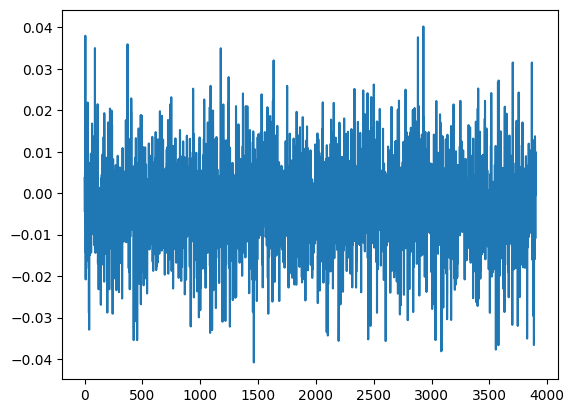

In [36]:
# cut a dataset to only keep the good data

# manually check where to cut...
q = load_dataset(name_map[8], "BCM_GUN")
plt.plot( q[10500:14400] )


In [11]:
import json
from collections import Counter

SKIP_VARS = ("BTV0125/image2D",)  # int16 images: cannot hold NaN, and ~470 MB per chunk to read


def bad_rows(obj, n):
    """Number of shots with no usable value: NaN/inf anywhere in the shot, empty ragged shot, empty string."""
    if is_ragged(obj):
        return sum(obj[k].size == 0 or not np.isfinite(obj[k][()]).all() for k in obj)
    if obj.dtype.kind in "iub":                       # integers/bools cannot be NaN
        return 0
    a = obj[()].reshape(n, -1)
    if a.dtype.kind == "f":
        return int((~np.isfinite(a)).any(axis=1).sum())
    return int(np.isin(a, [b"", b"None", b"nan"]).any(axis=1).sum())  # strings


def bad_data(chunks):
    """{variable: % of shots that are bad} for one run; variables absent from a chunk count as bad there."""
    bad, n_total, seen = Counter(), 0, {}
    for fp in chunks:
        with h5py.File(fp, "r") as f:
            n = int(f.attrs["n_shots"])
            names = set(list_variables(fp)) - set(SKIP_VARS)
            for var in names:
                bad[var] += bad_rows(f[var], n)
            for var in set(seen) - names:             # known variable, missing in this chunk
                bad[var] += n
            for var in names - set(seen):             # new variable: all earlier shots missing it
                bad[var] += n_total
                seen[var] = True
            n_total += n
    return {v: round(100 * c / n_total, 2) for v, c in sorted(bad.items(), key=lambda x: -x[1]) if c}


report = {run: bad_data(chunks) for run, chunks in runs.items()}
print(json.dumps(report, indent=2))

{
  "acquisition_2026-10-06_21-57-43": {
    "BTV0125/imagePositionSet2": 3.04,
    "BTV0125/projDataSet1Original": 3.04,
    "BTV0125/projDataSet1": 3.03,
    "BTV0125/projDataSet2Original": 3.03,
    "BTV0125/projDataSet2": 3.03,
    "BTV0125/imagePositionSet1": 3.02
  },
  "acquisition_2026-10-07_20-55-58": {
    "BTV0125/projDataSet2Original": 10.61,
    "BTV0125/projDataSet1": 10.61,
    "BTV0125/imagePositionSet2": 10.61,
    "BTV0125/projDataSet1Original": 10.61,
    "BTV0125/projDataSet2": 10.61,
    "BTV0125/imagePositionSet1": 10.61
  },
  "acquisition_2026-10-07_21-42-34": {
    "BTV0125/projDataSet2Original": 24.32,
    "BTV0125/projDataSet1": 24.32,
    "BTV0125/imagePositionSet2": 24.32,
    "BTV0125/projDataSet1Original": 24.32,
    "BTV0125/projDataSet2": 24.32,
    "BTV0125/imagePositionSet1": 24.32
  },
  "acquisition_2026-10-07_21-43-26": {
    "BTV0125/imagePositionSet2": 8.28,
    "BTV0125/imagePositionSet1": 8.28,
    "BTV0125/projDataSet1": 8.26,
    "BTV0125/pro

In [11]:
import json
from collections import Counter

SKIP_VARS = ("BTV0125/image2D",)  # int16 images: cannot hold NaN, and ~470 MB per chunk to read


def bad_rows(obj, n):
    """Number of shots with no usable value: NaN/inf anywhere in the shot, empty ragged shot, empty string."""
    if is_ragged(obj):
        return sum(obj[k].size == 0 or not np.isfinite(obj[k][()]).all() for k in obj)
    if obj.dtype.kind in "iub":                       # integers/bools cannot be NaN
        return 0
    a = obj[()].reshape(n, -1)
    if a.dtype.kind == "f":
        return int((~np.isfinite(a)).any(axis=1).sum())
    return int(np.isin(a, [b"", b"None", b"nan"]).any(axis=1).sum())  # strings


def bad_data(chunks):
    """{variable: % of shots that are bad} for one run; variables absent from a chunk count as bad there."""
    bad, n_total, seen = Counter(), 0, {}
    for fp in chunks:
        with h5py.File(fp, "r") as f:
            n = int(f.attrs["n_shots"])
            names = set(list_variables(fp)) - set(SKIP_VARS)
            for var in names:
                bad[var] += bad_rows(f[var], n)
            for var in set(seen) - names:             # known variable, missing in this chunk
                bad[var] += n
            for var in names - set(seen):             # new variable: all earlier shots missing it
                bad[var] += n_total
                seen[var] = True
            n_total += n
    return {v: round(100 * c / n_total, 2) for v, c in sorted(bad.items(), key=lambda x: -x[1]) if c}


report = {run: bad_data(chunks) for run, chunks in runs.items()}
print(json.dumps(report, indent=2))

{
  "acquisition_2026-10-06_21-57-43": {
    "BTV0125/imagePositionSet2": 3.04,
    "BTV0125/projDataSet1Original": 3.04,
    "BTV0125/projDataSet1": 3.03,
    "BTV0125/projDataSet2Original": 3.03,
    "BTV0125/projDataSet2": 3.03,
    "BTV0125/imagePositionSet1": 3.02
  },
  "acquisition_2026-10-07_20-55-58": {
    "BTV0125/projDataSet2Original": 10.61,
    "BTV0125/projDataSet1": 10.61,
    "BTV0125/imagePositionSet2": 10.61,
    "BTV0125/projDataSet1Original": 10.61,
    "BTV0125/projDataSet2": 10.61,
    "BTV0125/imagePositionSet1": 10.61
  },
  "acquisition_2026-10-07_21-42-34": {
    "BTV0125/projDataSet2Original": 24.32,
    "BTV0125/projDataSet1": 24.32,
    "BTV0125/imagePositionSet2": 24.32,
    "BTV0125/projDataSet1Original": 24.32,
    "BTV0125/projDataSet2": 24.32,
    "BTV0125/imagePositionSet1": 24.32
  },
  "acquisition_2026-10-07_21-43-26": {
    "BTV0125/imagePositionSet2": 8.28,
    "BTV0125/imagePositionSet1": 8.28,
    "BTV0125/projDataSet1": 8.26,
    "BTV0125/pro

In [ ]:
MIN_WAVE_LEN = 10  # per-shot arrays at least this long count as waveforms

def waveform_names(f):
    """Float datasets with a per-shot array of >= MIN_WAVE_LEN samples (images skipped)."""
    out = []
    for var in list_variables(f.filename):
        obj = f[var]
        if (isinstance(obj, h5py.Dataset) and obj.dtype.kind == "f" and var not in SKIP_VARS
                and obj.ndim > 1 and np.prod(obj.shape[1:]) >= MIN_WAVE_LEN):
            out.append(var)
    return out


def quality_checks(chunks):
    """
    {variable: {check: % of shots}} for one run, only non-zero entries.
      stale  : stamp equal to the previous shot's stamp (device did not update)
      repeat : waveform identical to the previous shot's waveform
      zero   : waveform all zeros
      flat   : waveform constant (includes zero)
    The previous shot of a chunk's first shot is the last shot of the previous chunk.
    """
    counts, last, n_total = {}, {}, 0

    def add(var, check, k):
        counts.setdefault(var, Counter())[check] += int(k)

    for fp in chunks:
        with h5py.File(fp, "r") as f:
            n = int(f.attrs["n_shots"])
            for var in f:
                if var.endswith("_stamp") and var != "trigger_stamp":
                    s = f[var][()]
                    prev = np.r_[last.get(var, np.nan), s[:-1]]
                    add(var.removesuffix("_stamp"), "stale", (s == prev).sum())
                    last[var] = s[-1]
            for var in waveform_names(f):
                a = f[var][()].reshape(n, -1)
                p = last.get(var)
                if p is None or p.shape[1] != a.shape[1]:   # first chunk, or length changed
                    p = np.full((1, a.shape[1]), np.nan)
                prev = np.vstack([p, a[:-1]])
                add(var, "repeat", (a == prev).all(axis=1).sum())
                add(var, "zero", (a == 0).all(axis=1).sum())
                add(var, "flat", (np.ptp(a, axis=1) == 0).sum())
                last[var] = a[-1:]
            n_total += n

    report = {}
    for var, c in sorted(counts.items()):
        pct = {k: round(100 * v / n_total, 2) for k, v in c.items() if v}
        if pct:
            report[var] = pct
    return report


quality = {run: quality_checks(chunks) for run, chunks in runs.items()}
print(json.dumps(quality, indent=2))